# Epidemiological Layer — PM₂.₅ Forecast-to-Health Burden Pipeline

**Study objective:** Convert the selected Random Forest (RF) model's continuous hourly PM₂.₅ predictions into a 2025 annual exposure estimate and propagate that exposure through the established epidemiological framework to estimate disease-specific relative risk (RR), population attributable fraction (PAF), attributable deaths, and attributable DALYs for:

- Stroke
- Ischemic Heart Disease (IHD)
- Lower Respiratory Infections (LRI/ALRI)
- Chronic Obstructive Pulmonary Disease (COPD)



### Important scope rule

The epidemiological health layer is **independent of the parallel SVM/AQI classification track**. AQI categories are not used as epidemiological exposure inputs.


## 1. Decision → Justification

**Decision:** Use the full-feature RF model and generate a complete prospective 2025 exposure series.

**Justification:** The thesis selects the optimized full-feature Random Forest as the best continuous PM₂.₅ regression model. The health module requires an annual exposure metric, so a complete calendar-year 2025 prediction series is required. Training uses 2024 target observations and prediction uses 2025 target timestamps to avoid training on the health-assessment year.

**Decision:** Use annual mean predicted continuous PM₂.₅ as \(C_{2025}\).

**Justification:** The thesis states that hourly predictions are aggregated to an annual average exposure value for the epidemiological equations, while the GBD health baseline is annual.

**Decision:** Use the GBD Results Tool's **Cause of death or injury → Number** values as baseline deaths/DALYs.

**Justification:** These are total cause-specific burdens. The supplied PM₂.₅ risk-factor dataset already contains PM₂.₅-attributable rate/percent measures and therefore must not be used as the baseline denominator because that would double-attribute the burden.

In [1]:
# 2. Imports, paths, and reproducibility

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ------------------------------------------------------------------
# Portable path discovery
# ------------------------------------------------------------------
# The notebook can be run in the project folder, Colab, or locally.
# Adjust DATA_DIR manually only if automatic discovery does not find
# the required files.
# ------------------------------------------------------------------

candidate_dirs = [
    Path.cwd(),
    Path("/mnt/data"),
    Path("/content"),
    Path("/content/data"),
    Path("/epidemiology/data"),
    Path(r"C:\Users\HP\Desktop\Systematic Review\Reviews\Project Upgrade\Air Quality"),
    Path(r"C:\Users\HP\Desktop\Systematic Review\Reviews\Project Upgrade\Air Quality\data"),
]

required_for_model = "AirQuality_Full_Model_Dataset.csv"

DATA_DIR = next(
    (
        d for d in candidate_dirs
        if d.exists() and (d / required_for_model).exists()
    ),
    Path.cwd()
)

OUTPUT_DIR = DATA_DIR / "epidemiological_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FULL_PATH = DATA_DIR / "AirQuality_Full_Model_Dataset.csv"
CLEAN_PATH = DATA_DIR / "air_quality_model.csv"
RR_PATH = DATA_DIR / "RR_beta.xlsx"
IHME_DEATHS_PATH = DATA_DIR / "IHME_2023_Deaths.xlsx"
IHME_DALYS_PATH = DATA_DIR / "IHME_2023_DALYs.xlsx"

print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

for p in [
    FULL_PATH, CLEAN_PATH, RR_PATH,
    IHME_DEATHS_PATH, IHME_DALYS_PATH
]:
    print(f"{p.name:40s} -> {'FOUND' if p.exists() else 'MISSING'}")


DATA_DIR: c:\Users\HP\Desktop\Systematic Review\Reviews\Project Upgrade\Air Quality
OUTPUT_DIR: c:\Users\HP\Desktop\Systematic Review\Reviews\Project Upgrade\Air Quality\epidemiological_outputs
AirQuality_Full_Model_Dataset.csv        -> FOUND
air_quality_model.csv                    -> FOUND
RR_beta.xlsx                             -> FOUND
IHME_2023_Deaths.xlsx                    -> FOUND
IHME_2023_DALYs.xlsx                     -> FOUND


In [2]:
# 3. Load environmental modelling and timestamp datasets

full = pd.read_csv(FULL_PATH)
clean = pd.read_csv(CLEAN_PATH)

clean["date"] = pd.to_datetime(clean["date"], errors="coerce")

print("Full modelling dataset shape:", full.shape)
print("Timestamp/engineered dataset shape:", clean.shape)
print("Timestamp range:", clean["date"].min(), "to", clean["date"].max())

assert full.shape == (17519, 29), (
    f"Unexpected full modelling shape: {full.shape}"
)
assert clean.shape[0] == 17520, (
    f"Unexpected timestamp dataset row count: {clean.shape[0]}"
)
assert clean["date"].notna().all()
assert clean["date"].is_monotonic_increasing
assert clean["date"].duplicated().sum() == 0

print("Environmental dataset integrity checks PASSED.")


Full modelling dataset shape: (17519, 29)
Timestamp/engineered dataset shape: (17520, 35)
Timestamp range: 2024-01-02 00:00:00 to 2025-12-31 23:00:00
Environmental dataset integrity checks PASSED.


In [3]:
# 4. Verify exact row alignment and one-hour-ahead target construction

predictor_cols = [c for c in full.columns if c != "Target_PM2.5"]

assert len(predictor_cols) == 28
assert len(full) == len(clean) - 1

comparison = clean.loc[:len(full)-1, predictor_cols].reset_index(drop=True)
full_predictors = full[predictor_cols].reset_index(drop=True)

mismatch_cells = int(
    comparison.ne(full_predictors).to_numpy().sum()
)

target_expected = (
    clean["PM2.5"]
    .shift(-1)
    .iloc[:len(full)]
    .reset_index(drop=True)
)

target_actual = full["Target_PM2.5"].reset_index(drop=True)

target_max_abs_diff = float(
    np.max(np.abs(target_actual - target_expected))
)

print("Number of RF predictors:", len(predictor_cols))
print("Mismatched predictor cells:", mismatch_cells)
print("Maximum target alignment difference:", target_max_abs_diff)

assert mismatch_cells == 0
assert target_max_abs_diff == 0.0

print("Row alignment and one-hour-ahead target definition VERIFIED.")


Number of RF predictors: 28
Mismatched predictor cells: 0
Maximum target alignment difference: 0.0
Row alignment and one-hour-ahead target definition VERIFIED.


In [4]:
# 6. Construct input and target timestamps

model_df = full.copy()

model_df["input_timestamp"] = (
    clean["date"].iloc[:len(full)].to_numpy()
)

model_df["target_timestamp"] = (
    model_df["input_timestamp"] + pd.Timedelta(hours=1)
)

train_2024_mask = model_df["target_timestamp"].dt.year.eq(2024)
pred_2025_mask = model_df["target_timestamp"].dt.year.eq(2025)

train_df = model_df.loc[train_2024_mask].copy()
pred_2025_df = model_df.loc[pred_2025_mask].copy()

print("2024 training rows:", len(train_df))
print("2025 prediction rows:", len(pred_2025_df))
print("2025 target start:", pred_2025_df["target_timestamp"].min())
print("2025 target end:", pred_2025_df["target_timestamp"].max())

expected_2025_index = pd.date_range(
    "2025-01-01 00:00:00",
    "2025-12-31 23:00:00",
    freq="h"
)

assert len(pred_2025_df) == 8760
assert pred_2025_df["target_timestamp"].reset_index(drop=True).equals(
    pd.Series(expected_2025_index, name="target_timestamp")
)

print("Complete 2025 hourly target coverage VERIFIED: 8,760 hours.")


2024 training rows: 8759
2025 prediction rows: 8760
2025 target start: 2025-01-01 00:00:00
2025 target end: 2025-12-31 23:00:00
Complete 2025 hourly target coverage VERIFIED: 8,760 hours.


In [5]:
# 7. Prepare RF training and 2025 prediction matrices

X_train = train_df[predictor_cols].copy()
y_train = train_df["Target_PM2.5"].copy()
X_2025 = pred_2025_df[predictor_cols].copy()

assert X_train.shape[1] == 28
assert len(X_train) == len(y_train)
assert X_2025.shape[0] == 8760

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_2025:", X_2025.shape)


X_train: (8759, 28)
y_train: (8759,)
X_2025: (8760, 28)


## 8. Random Forest optimization

The same RF optimization procedure used in the regression study is reproduced:

- Random Forest Regressor
- `random_state=42`
- no feature scaling
- `TimeSeriesSplit(n_splits=5)`
- `GridSearchCV`
- scoring = negative RMSE
- the established 48-combination hyperparameter grid

Only the temporal purpose differs: here the fitted RF is used to generate a complete prospective 2025 exposure series for the epidemiological layer.

In [6]:
# 9. TimeSeriesSplit + GridSearchCV

tscv = TimeSeriesSplit(n_splits=5)

rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation RMSE:")
print(-grid_search.best_score_)

assert best_rf is not None


Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}

Best cross-validation RMSE:
4.42548673384935


In [7]:
# 10. Generate the complete 2025 one-hour-ahead PM₂.₅ prediction series

y_pred_2025 = best_rf.predict(X_2025)

predictions_2025 = pd.DataFrame({
    "target_timestamp": pred_2025_df["target_timestamp"].to_numpy(),
    "observed_PM2.5": pred_2025_df["Target_PM2.5"].to_numpy(),
    "predicted_PM2.5": y_pred_2025
})

predictions_2025["year"] = predictions_2025["target_timestamp"].dt.year

assert len(predictions_2025) == 8760
assert predictions_2025["target_timestamp"].is_monotonic_increasing
assert predictions_2025["target_timestamp"].duplicated().sum() == 0
assert predictions_2025["predicted_PM2.5"].notna().all()

display(predictions_2025.head())
display(predictions_2025.tail())

print("2025 prediction series VERIFIED: 8,760 hourly values.")


,target_timestamp,observed_PM2.5,predicted_PM2.5,year
0,2025-01-01 00:00:00,36.965166,29.969464,2025
1,2025-01-01 01:00:00,70.494120,38.045124,2025
2,2025-01-01 02:00:00,102.941881,66.229871,2025
3,2025-01-01 03:00:00,81.503535,90.672000,2025
4,2025-01-01 04:00:00,62.209174,71.502214,2025


,target_timestamp,observed_PM2.5,predicted_PM2.5,year
8755,2025-12-31 19:00:00,64.617278,33.013630,2025
8756,2025-12-31 20:00:00,68.951624,67.083949,2025
8757,2025-12-31 21:00:00,72.403154,64.553048,2025
8758,2025-12-31 22:00:00,64.702803,71.629389,2025
8759,2025-12-31 23:00:00,56.513579,63.741308,2025


2025 prediction series VERIFIED: 8,760 hourly values.


In [8]:
# 11. 2025 prospective prediction-period performance

y_true_2025 = predictions_2025["observed_PM2.5"]
y_pred_2025_eval = predictions_2025["predicted_PM2.5"]

mae_2025 = mean_absolute_error(y_true_2025, y_pred_2025_eval)
mse_2025 = mean_squared_error(y_true_2025, y_pred_2025_eval)
rmse_2025 = float(np.sqrt(mse_2025))
r2_2025 = r2_score(y_true_2025, y_pred_2025_eval)

observed_mean_2025 = float(y_true_2025.mean())
predicted_mean_2025 = float(y_pred_2025_eval.mean())
mean_bias_2025 = predicted_mean_2025 - observed_mean_2025

performance_2025 = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R2",
        "Observed annual mean",
        "Predicted annual mean",
        "Mean bias"
    ],
    "Value": [
        mae_2025,
        mse_2025,
        rmse_2025,
        r2_2025,
        observed_mean_2025,
        predicted_mean_2025,
        mean_bias_2025
    ]
})

display(performance_2025)


,Metric,Value
0,MAE,2.215269
1,MSE,13.144260
2,RMSE,3.625501
3,R2,0.909971
4,Observed annual mean,20.470589
5,Predicted annual mean,20.569335
6,Mean bias,0.098746


In [9]:
# 13. Calculate and verify annual predicted PM₂.₅ exposure

C_2025 = float(predictions_2025["predicted_PM2.5"].mean())

annual_exposure = pd.DataFrame({
    "year": [2025],
    "n_hourly_predictions": [len(predictions_2025)],
    "observed_annual_mean_PM2.5": [observed_mean_2025],
    "predicted_annual_mean_PM2.5_C": [C_2025],
    "mean_bias_PM2.5": [mean_bias_2025]
})

assert len(predictions_2025) == 8760
assert np.isfinite(C_2025)
assert C_2025 >= 0

print(f"2025 observed annual mean PM₂.₅: {observed_mean_2025:.6f} µg/m³")
print(f"2025 predicted annual mean C:   {C_2025:.6f} µg/m³")
print(f"Annual mean bias:                {mean_bias_2025:.6f} µg/m³")

display(annual_exposure)


2025 observed annual mean PM₂.₅: 20.470589 µg/m³
2025 predicted annual mean C:   20.569335 µg/m³
Annual mean bias:                0.098746 µg/m³


,year,n_hourly_predictions,observed_annual_mean_PM2.5,predicted_annual_mean_PM2.5_C,mean_bias_PM2.5
0,2025,8760,20.470589,20.569335,0.098746


In [10]:
# 14. Save the environmental prediction outputs

predictions_2025.to_csv(
    OUTPUT_DIR / "rf_2025_hourly_predictions.csv",
    index=False
)

annual_exposure.to_csv(
    OUTPUT_DIR / "annual_pm25_exposure.csv",
    index=False
)

performance_2025.to_csv(
    OUTPUT_DIR / "rf_2025_prediction_performance.csv",
    index=False
)

print("Saved environmental outputs.")


Saved environmental outputs.


# 15. Epidemiological health-risk module

The annual predicted exposure C_2025 is connected to the established disease-specific concentration-response relationships.



In [11]:
# 16. Load and verify the established RR/β workbook

assert RR_PATH.exists(), f"RR workbook not found: {RR_PATH}"

rr_raw = pd.read_excel(RR_PATH)

required_rr_cols = [
    "Target Pathology (GBD Cause Name)",
    "Peer-Reviewed RR (per 10μg/m3 increase)",
    "Derived Pipeline Constant (β)"
]

missing_rr_cols = [
    c for c in required_rr_cols if c not in rr_raw.columns
]

assert not missing_rr_cols, f"Missing RR/β columns: {missing_rr_cols}"

TARGET_DISEASES = [
    "Stroke (Cerebrovascular Disease)",
    "Ischemic Heart Disease (IHD)",
    "Lower Respiratory Infections (LRI)",
    "Chronic Obstructive Pulmonary Disease (COPD)"
]

rr_beta = rr_raw[
    rr_raw["Target Pathology (GBD Cause Name)"].isin(TARGET_DISEASES)
].copy()

assert set(rr_beta["Target Pathology (GBD Cause Name)"]) == set(TARGET_DISEASES)
assert len(rr_beta) == 4

# Lung cancer must not enter the health-burden calculation.
assert not rr_beta[
    "Target Pathology (GBD Cause Name)"
].str.contains("Lung Cancer", case=False, na=False).any()

rr_beta["RR_10"] = pd.to_numeric(
    rr_beta["Peer-Reviewed RR (per 10μg/m3 increase)"],
    errors="coerce"
)

rr_beta["beta_recalculated"] = np.log(rr_beta["RR_10"]) / 10.0

rr_beta["beta_workbook"] = pd.to_numeric(
    rr_beta["Derived Pipeline Constant (β)"],
    errors="coerce"
)

rr_beta["beta_difference"] = (
    rr_beta["beta_recalculated"] - rr_beta["beta_workbook"]
)

assert rr_beta["RR_10"].notna().all()
assert rr_beta["beta_workbook"].notna().all()

max_beta_discrepancy = float(
    rr_beta["beta_difference"].abs().max()
)

print("Maximum β discrepancy:", max_beta_discrepancy)

assert max_beta_discrepancy < 1e-4

rr_beta = rr_beta[
    [
        "Target Pathology (GBD Cause Name)",
        "RR_10",
        "beta_workbook",
        "beta_recalculated",
        "beta_difference"
    ]
].reset_index(drop=True)

display(rr_beta)

print("Four-disease RR/β verification PASSED.")


Maximum β discrepancy: 3.998467575714107e-06


,Target Pathology (GBD Cause Name),RR_10,beta_workbook,beta_recalculated,beta_difference
0,Stroke (Cerebrovascular Disease),1.11,0.01044,0.010436,-0.000004
1,Ischemic Heart Disease (IHD),1.15,0.01398,0.013976,-0.000004
2,Lower Respiratory Infections (LRI),1.15,0.01398,0.013976,-0.000004
3,Chronic Obstructive Pulmonary Disease (COPD),1.08,0.00770,0.007696,-0.000004


Four-disease RR/β verification PASSED.


In [12]:
# 17. Calculate excess annual exposure, RR, and PAF

TMREL = 5.0  # µg/m³, as specified for the epidemiological module

epi = rr_beta[[
    "Target Pathology (GBD Cause Name)",
    "RR_10",
    "beta_recalculated"
]].copy()

epi["annual_exposure_C"] = C_2025
epi["TMREL"] = TMREL

# Exposure above the counterfactual/reference level.
epi["delta_C"] = (
    epi["annual_exposure_C"] - epi["TMREL"]
).clip(lower=0.0)

# Log-linear concentration-response.
epi["RR"] = np.exp(
    epi["beta_recalculated"] * epi["delta_C"]
)

# Population attributable fraction.
epi["PAF"] = (
    (epi["RR"] - 1.0) / epi["RR"]
)

# Numerical safeguards.
epi["RR"] = epi["RR"].clip(lower=1.0)
epi["PAF"] = epi["PAF"].clip(lower=0.0, upper=1.0)

assert len(epi) == 4
assert epi["RR"].notna().all()
assert epi["PAF"].notna().all()
assert (epi["RR"] >= 1).all()
assert ((epi["PAF"] >= 0) & (epi["PAF"] <= 1)).all()

print(f"Annual predicted exposure C: {C_2025:.6f} µg/m³")
print(f"TMREL: {TMREL:.2f} µg/m³")
print(f"Excess exposure ΔC: {max(C_2025-TMREL, 0):.6f} µg/m³")

display(
    epi[[
        "Target Pathology (GBD Cause Name)",
        "annual_exposure_C",
        "TMREL",
        "delta_C",
        "beta_recalculated",
        "RR",
        "PAF"
    ]]
)


Annual predicted exposure C: 20.569335 µg/m³
TMREL: 5.00 µg/m³
Excess exposure ΔC: 15.569335 µg/m³


,Target Pathology (GBD Cause Name),annual_exposure_C,TMREL,delta_C,beta_recalculated,RR,PAF
0,Stroke (Cerebrovascular Disease),20.569335,5.0,15.569335,0.010436,1.176427,0.149968
1,Ischemic Heart Disease (IHD),20.569335,5.0,15.569335,0.013976,1.243090,0.195553
2,Lower Respiratory Infections (LRI),20.569335,5.0,15.569335,0.013976,1.243090,0.195553
3,Chronic Obstructive Pulmonary Disease (COPD),20.569335,5.0,15.569335,0.007696,1.127298,0.112923


In [13]:
# 19. Load and clean the GBD 2023 baseline Deaths and DALYs Excel files

assert IHME_DEATHS_PATH.exists(), f"Deaths file not found: {IHME_DEATHS_PATH}"
assert IHME_DALYS_PATH.exists(), f"DALYs file not found: {IHME_DALYS_PATH}"

# The Excel files were prepared from screenshots, so row 0 contains
# the original column headings and the actual header begins on row 1.
deaths = pd.read_excel(IHME_DEATHS_PATH, header=1)
dalys = pd.read_excel(IHME_DALYS_PATH, header=1)

deaths.columns = [str(c).strip() for c in deaths.columns]
dalys.columns = [str(c).strip() for c in dalys.columns]

required_baseline_cols = [
    "Metric", "Cause", "Age", "Sex", "Year", "Value", "Upper", "Lower"
]

assert list(deaths.columns) == required_baseline_cols, deaths.columns.tolist()
assert list(dalys.columns) == required_baseline_cols, dalys.columns.tolist()

# Convert screenshot-derived numeric text robustly.
def parse_numeric_value(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().replace(" ", "")
    # The DALYs Stroke upper bound was transcribed as "1,096.440.13".
    # Interpret the final period as the decimal separator and remove
    # earlier grouping punctuation.
    if s.count(".") > 1:
        parts = s.split(".")
        s = "".join(parts[:-1]) + "." + parts[-1]
    s = s.replace(",", "")
    return float(s)

for df in [deaths, dalys]:
    for col in ["Value", "Upper", "Lower"]:
        df[col] = df[col].map(parse_numeric_value)

print("Deaths baseline:")
display(deaths)

print("\nDALYs baseline:")
display(dalys)


Deaths baseline:


,Metric,Cause,Age,Sex,Year,Value,Upper,Lower
0,Number,Acute lower respiratory infection,All ages,Both,2023,17787.67,23286.74,13322.11
1,Number,Ischemic heart disease,All ages,Both,2023,16355.04,21219.32,11902.29
2,Number,Stroke,All ages,Both,2023,28749.67,35574.48,22120.44
3,Number,Chronic obstructive Pulmonary disease,All ages,Both,2023,2138.30,3073.32,1470.44



DALYs baseline:


,Metric,Cause,Age,Sex,Year,Value,Upper,Lower
0,Number,Stroke,All ages,Both,2023,885435.86,1096440.13,690752.34
1,Number,Acute lower respiratory infection,All ages,Both,2023,723042.35,926462.89,549574.97
2,Number,Ischemic heart disease,All ages,Both,2023,445437.17,592589.80,333742.97
3,Number,Chronic obstructive Pulmonary disease,All ages,Both,2023,80161.49,103299.91,62148.77


In [15]:
# 20. Validate GBD baseline scope and map GBD cause names
#     to the four diseases used in the epidemiological analysis.

EXPECTED_META = {
    "Metric": "Number",
    "Age": "All ages",
    "Sex": "Both",
    "Year": 2023
}

# ------------------------------------------------------------
# 1. Validate metadata
# ------------------------------------------------------------

for name, df in [("Deaths", deaths), ("DALYs", dalys)]:

    for col, expected in EXPECTED_META.items():

        values = (
            df[col]
            .astype(str)
            .str.strip()
            .unique()
        )

        assert len(values) == 1 and str(expected) in values, (
            f"{name}: unexpected {col} values: {values}"
        )

    assert len(df) == 4, (
        f"{name}: expected 4 disease rows, found {len(df)}"
    )

    assert df["Value"].notna().all(), (
        f"{name}: missing Value estimates."
    )

    assert df["Upper"].notna().all(), (
        f"{name}: missing Upper estimates."
    )

    assert df["Lower"].notna().all(), (
        f"{name}: missing Lower estimates."
    )

    assert (df["Lower"] <= df["Value"]).all(), (
        f"{name}: Lower bound exceeds point estimate."
    )

    assert (df["Value"] <= df["Upper"]).all(), (
        f"{name}: point estimate exceeds Upper bound."
    )


# ------------------------------------------------------------
# 2. Inspect the ACTUAL cause names in the Excel files
# ------------------------------------------------------------

print("Actual causes in Deaths file:")
print(deaths["Cause"].astype(str).str.strip().tolist())

print("\nActual causes in DALYs file:")
print(dalys["Cause"].astype(str).str.strip().tolist())


# ------------------------------------------------------------
# 3. Normalize cause names
# ------------------------------------------------------------
# The Excel files were prepared manually from GBD screenshots.
# Therefore, mapping is performed after normalization rather
# than relying on exact capitalization.

def normalize_cause_name(value):

    if pd.isna(value):
        return ""

    return (
        str(value)
        .strip()
        .lower()
        .replace("  ", " ")
    )


# ------------------------------------------------------------
# 4. Map normalized GBD causes to study disease names
# ------------------------------------------------------------

CAUSE_MAP_NORMALIZED = {

    "stroke":
        "Stroke (Cerebrovascular Disease)",

    "ischemic heart disease":
        "Ischemic Heart Disease (IHD)",

    "chronic obstructive pulmonary disease":
        "Chronic Obstructive Pulmonary Disease (COPD)",

    "acute lower respiratory infection":
        "Lower Respiratory Infections (LRI)",

    "lower respiratory infections":
        "Lower Respiratory Infections (LRI)",

    "lower respiratory infection":
        "Lower Respiratory Infections (LRI)"
}


deaths["cause_normalized"] = (
    deaths["Cause"]
    .map(normalize_cause_name)
)

dalys["cause_normalized"] = (
    dalys["Cause"]
    .map(normalize_cause_name)
)


deaths["disease"] = (
    deaths["cause_normalized"]
    .map(CAUSE_MAP_NORMALIZED)
)

dalys["disease"] = (
    dalys["cause_normalized"]
    .map(CAUSE_MAP_NORMALIZED)
)


# ------------------------------------------------------------
# 5. STOP-GATE: identify any unmapped causes
# ------------------------------------------------------------

unmapped_deaths = deaths.loc[
    deaths["disease"].isna(),
    "Cause"
].tolist()

unmapped_dalys = dalys.loc[
    dalys["disease"].isna(),
    "Cause"
].tolist()


if unmapped_deaths:
    raise ValueError(
        "Deaths file contains unmapped cause name(s): "
        f"{unmapped_deaths}"
    )

if unmapped_dalys:
    raise ValueError(
        "DALYs file contains unmapped cause name(s): "
        f"{unmapped_dalys}"
    )


# ------------------------------------------------------------
# 6. Verify exact four-disease scope
# ------------------------------------------------------------

assert set(deaths["disease"]) == set(TARGET_DISEASES), (
    "Deaths file does not contain exactly the four study diseases."
)

assert set(dalys["disease"]) == set(TARGET_DISEASES), (
    "DALYs file does not contain exactly the four study diseases."
)

assert len(deaths) == 4
assert len(dalys) == 4


# ------------------------------------------------------------
# 7. Explicitly verify that lung cancer is absent
# ------------------------------------------------------------

assert not deaths["Cause"].astype(str).str.contains(
    "lung cancer",
    case=False,
    na=False
).any()

assert not dalys["Cause"].astype(str).str.contains(
    "lung cancer",
    case=False,
    na=False
).any()


# ------------------------------------------------------------
# 8. Prepare clean baseline deaths table
# ------------------------------------------------------------

deaths_clean = deaths[[
    "disease",
    "Value",
    "Upper",
    "Lower"
]].rename(columns={

    "Value":
        "baseline_deaths",

    "Upper":
        "baseline_deaths_upper",

    "Lower":
        "baseline_deaths_lower"
})


# ------------------------------------------------------------
# 9. Prepare clean baseline DALYs table
# ------------------------------------------------------------

dalys_clean = dalys[[
    "disease",
    "Value",
    "Upper",
    "Lower"
]].rename(columns={

    "Value":
        "baseline_dalys",

    "Upper":
        "baseline_dalys_upper",

    "Lower":
        "baseline_dalys_lower"
})


# ------------------------------------------------------------
# 10. Merge deaths and DALYs
# ------------------------------------------------------------

gbd_baseline = deaths_clean.merge(
    dalys_clean,
    on="disease",
    how="inner",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 11. Final validation
# ------------------------------------------------------------

assert len(gbd_baseline) == 4

assert set(
    gbd_baseline["disease"]
) == set(TARGET_DISEASES)

for col in [
    "baseline_deaths",
    "baseline_deaths_lower",
    "baseline_deaths_upper",
    "baseline_dalys",
    "baseline_dalys_lower",
    "baseline_dalys_upper"
]:

    assert gbd_baseline[col].notna().all(), (
        f"Missing values found in {col}"
    )

print("\n" + "=" * 70)
print("GBD BASELINE VALIDATION PASSED")
print("=" * 70)

display(
    gbd_baseline.sort_values("disease")
)

Actual causes in Deaths file:
['Acute lower respiratory infection', 'Ischemic  heart disease', 'Stroke', 'Chronic obstructive Pulmonary disease']

Actual causes in DALYs file:
['Stroke', 'Acute lower respiratory infection', 'Ischemic heart disease', 'Chronic obstructive Pulmonary disease']

GBD BASELINE VALIDATION PASSED


,disease,baseline_deaths,baseline_deaths_upper,baseline_deaths_lower,baseline_dalys,baseline_dalys_upper,baseline_dalys_lower
3,Chronic Obstructive Pulmonary Disease (COPD),2138.30,3073.32,1470.44,80161.49,103299.91,62148.77
1,Ischemic Heart Disease (IHD),16355.04,21219.32,11902.29,445437.17,592589.80,333742.97
0,Lower Respiratory Infections (LRI),17787.67,23286.74,13322.11,723042.35,926462.89,549574.97
2,Stroke (Cerebrovascular Disease),28749.67,35574.48,22120.44,885435.86,1096440.13,690752.34


In [19]:
# 22. Merge RR/PAF with GBD baseline burden and calculate attributable burden
#
# Epidemiological chain:
# Annual PM₂.₅ exposure → RR → PAF → GBD baseline
# → attributable deaths and attributable DALYs
#
# IMPORTANT:
# epi currently uses:
# "Target Pathology (GBD Cause Name)"
# as its disease identifier.
#
# gbd_baseline uses:
# "disease"
#
# We standardize the epi key before merging.


# ============================================================
# 1. Standardize the disease identifier in epi
# ============================================================

assert "Target Pathology (GBD Cause Name)" in epi.columns, (
    "Expected disease identifier was not found in epi."
)

assert "disease" in gbd_baseline.columns, (
    "Expected 'disease' identifier was not found in gbd_baseline."
)

epi_for_merge = epi.rename(
    columns={
        "Target Pathology (GBD Cause Name)": "disease"
    }
).copy()


# ============================================================
# 2. Verify disease coverage before merging
# ============================================================

print("Diseases in epi:")
print(sorted(epi_for_merge["disease"].tolist()))

print("\nDiseases in GBD baseline:")
print(sorted(gbd_baseline["disease"].tolist()))


# Verify the four study diseases are represented
assert set(epi_for_merge["disease"]) == set(TARGET_DISEASES), (
    "epi does not contain exactly the four study diseases."
)

assert set(gbd_baseline["disease"]) == set(TARGET_DISEASES), (
    "gbd_baseline does not contain exactly the four study diseases."
)


# ============================================================
# 3. Merge RR/PAF results with validated GBD baseline
# ============================================================

results = epi_for_merge.merge(
    gbd_baseline,
    on="disease",
    how="inner",
    validate="one_to_one"
)


# ============================================================
# 4. Verify final disease scope
# ============================================================

assert len(results) == 4

assert set(results["disease"]) == set(TARGET_DISEASES)

assert not results["disease"].str.contains(
    "Lung Cancer",
    case=False,
    na=False
).any()


# ============================================================
# 5. Verify epidemiological inputs
# ============================================================

for col in [
    "annual_exposure_C",
    "TMREL",
    "delta_C",
    "RR",
    "PAF"
]:
    assert results[col].notna().all(), (
        f"Missing values detected in {col}"
    )

assert (results["annual_exposure_C"] >= 0).all()

assert (results["TMREL"] >= 0).all()

assert (results["delta_C"] >= 0).all()

assert (results["RR"] >= 1).all()

assert (results["PAF"] >= 0).all()

assert (results["PAF"] <= 1).all()


# ============================================================
# 6. Calculate attributable deaths
# ============================================================

results["attributable_deaths"] = (
    results["PAF"]
    * results["baseline_deaths"]
)


# ============================================================
# 7. Calculate attributable DALYs
# ============================================================

results["attributable_dalys"] = (
    results["PAF"]
    * results["baseline_dalys"]
)


# ============================================================
# 8. Propagate GBD mortality uncertainty
#
# These bounds propagate the GBD baseline uncertainty
# while holding PAF constant.
#
# They are NOT complete epidemiological confidence intervals.
# ============================================================

results["attributable_deaths_lower"] = (
    results["PAF"]
    * results["baseline_deaths_lower"]
)

results["attributable_deaths_upper"] = (
    results["PAF"]
    * results["baseline_deaths_upper"]
)


# ============================================================
# 9. Propagate GBD DALY uncertainty
# ============================================================

results["attributable_dalys_lower"] = (
    results["PAF"]
    * results["baseline_dalys_lower"]
)

results["attributable_dalys_upper"] = (
    results["PAF"]
    * results["baseline_dalys_upper"]
)


# ============================================================
# 10. Attributable burden as percentage of baseline
# ============================================================

results["attributable_deaths_pct"] = (
    results["attributable_deaths"]
    / results["baseline_deaths"]
    * 100
)

results["attributable_dalys_pct"] = (
    results["attributable_dalys"]
    / results["baseline_dalys"]
    * 100
)


# ============================================================
# 11. Verify calculated burden
# ============================================================

for col in [
    "attributable_deaths",
    "attributable_deaths_lower",
    "attributable_deaths_upper",
    "attributable_dalys",
    "attributable_dalys_lower",
    "attributable_dalys_upper"
]:

    assert results[col].notna().all(), (
        f"Missing values detected in {col}"
    )

    assert (results[col] >= 0).all(), (
        f"Negative values detected in {col}"
    )


# Lower ≤ point estimate ≤ upper

assert (
    results["attributable_deaths_lower"]
    <= results["attributable_deaths"]
).all()

assert (
    results["attributable_deaths"]
    <= results["attributable_deaths_upper"]
).all()

assert (
    results["attributable_dalys_lower"]
    <= results["attributable_dalys"]
).all()

assert (
    results["attributable_dalys"]
    <= results["attributable_dalys_upper"]
).all()


# ============================================================
# 12. Verify attributable percentage = PAF
# ============================================================

assert np.allclose(
    results["attributable_deaths_pct"],
    results["PAF"] * 100,
    atol=1e-10
)

assert np.allclose(
    results["attributable_dalys_pct"],
    results["PAF"] * 100,
    atol=1e-10
)


# ============================================================
# 13. Display final disease-specific results
# ============================================================

display(
    results[[
        "disease",
        "annual_exposure_C",
        "TMREL",
        "delta_C",
        "RR",
        "PAF",
        "attributable_deaths_pct",
        "baseline_deaths",
        "attributable_deaths",
        "attributable_deaths_lower",
        "attributable_deaths_upper",
        "baseline_dalys",
        "attributable_dalys",
        "attributable_dalys_lower",
        "attributable_dalys_upper"
    ]].sort_values("disease")
)


# ============================================================
# 14. Summary
# ============================================================

print("\n" + "=" * 80)
print("ATTRIBUTABLE HEALTH-BURDEN CALCULATION COMPLETED")
print("=" * 80)

print(
    f"Annual predicted PM₂.₅ exposure: "
    f"{results['annual_exposure_C'].iloc[0]:.6f} µg/m³"
)

print(
    f"TMREL: "
    f"{results['TMREL'].iloc[0]:.6f} µg/m³"
)

print(
    f"Excess exposure above TMREL: "
    f"{results['delta_C'].iloc[0]:.6f} µg/m³"
)

print(
    f"Study diseases included: "
    f"{results['disease'].nunique()}"
)

print(
    f"Total baseline deaths: "
    f"{results['baseline_deaths'].sum():,.2f}"
)

print(
    f"Total attributable deaths: "
    f"{results['attributable_deaths'].sum():,.2f}"
)

print(
    f"Total baseline DALYs: "
    f"{results['baseline_dalys'].sum():,.2f}"
)

print(
    f"Total attributable DALYs: "
    f"{results['attributable_dalys'].sum():,.2f}"
)

Diseases in epi:
['Chronic Obstructive Pulmonary Disease (COPD)', 'Ischemic Heart Disease (IHD)', 'Lower Respiratory Infections (LRI)', 'Stroke (Cerebrovascular Disease)']

Diseases in GBD baseline:
['Chronic Obstructive Pulmonary Disease (COPD)', 'Ischemic Heart Disease (IHD)', 'Lower Respiratory Infections (LRI)', 'Stroke (Cerebrovascular Disease)']


,disease,annual_exposure_C,TMREL,delta_C,RR,PAF,attributable_deaths_pct,baseline_deaths,attributable_deaths,attributable_deaths_lower,attributable_deaths_upper,baseline_dalys,attributable_dalys,attributable_dalys_lower,attributable_dalys_upper
3,Chronic Obstructive Pulmonary Disease (COPD),20.569335,5.0,15.569335,1.127298,0.112923,11.292276,2138.30,241.462746,166.046149,347.047789,80161.49,9052.057019,7018.010889,11664.911361
1,Ischemic Heart Disease (IHD),20.569335,5.0,15.569335,1.243090,0.195553,19.555289,16355.04,3198.275285,2327.527169,4149.499281,445437.17,87106.524472,65264.401226,115882.646066
2,Lower Respiratory Infections (LRI),20.569335,5.0,15.569335,1.243090,0.195553,19.555289,17787.67,3478.430218,2605.177068,4553.789231,723042.35,141393.018806,107470.971885,181172.492633
0,Stroke (Cerebrovascular Disease),20.569335,5.0,15.569335,1.176427,0.149968,14.996827,28749.67,4311.538410,3317.364224,5335.043391,885435.86,132787.288333,103590.936714,164431.234671



ATTRIBUTABLE HEALTH-BURDEN CALCULATION COMPLETED
Annual predicted PM₂.₅ exposure: 20.569335 µg/m³
TMREL: 5.000000 µg/m³
Excess exposure above TMREL: 15.569335 µg/m³
Study diseases included: 4
Total baseline deaths: 65,030.68
Total attributable deaths: 11,229.71
Total baseline DALYs: 2,134,076.87
Total attributable DALYs: 370,338.89


In [20]:
# 23. Produce the final four-disease burden summary

summary_cols = [
    "disease",
    "RR",
    "PAF",
    "baseline_deaths",
    "baseline_deaths_lower",
    "baseline_deaths_upper",
    "attributable_deaths",
    "attributable_deaths_lower",
    "attributable_deaths_upper",
    "baseline_dalys",
    "baseline_dalys_lower",
    "baseline_dalys_upper",
    "attributable_dalys",
    "attributable_dalys_lower",
    "attributable_dalys_upper"
]

final_health_results = results[summary_cols].copy()

totals = pd.DataFrame({
    "disease": ["Four-disease total"],
    "RR": [np.nan],
    "PAF": [np.nan],
    "baseline_deaths": [results["baseline_deaths"].sum()],
    "baseline_deaths_lower": [results["baseline_deaths_lower"].sum()],
    "baseline_deaths_upper": [results["baseline_deaths_upper"].sum()],
    "attributable_deaths": [results["attributable_deaths"].sum()],
    "attributable_deaths_lower": [results["attributable_deaths_lower"].sum()],
    "attributable_deaths_upper": [results["attributable_deaths_upper"].sum()],
    "baseline_dalys": [results["baseline_dalys"].sum()],
    "baseline_dalys_lower": [results["baseline_dalys_lower"].sum()],
    "baseline_dalys_upper": [results["baseline_dalys_upper"].sum()],
    "attributable_dalys": [results["attributable_dalys"].sum()],
    "attributable_dalys_lower": [results["attributable_dalys_lower"].sum()],
    "attributable_dalys_upper": [results["attributable_dalys_upper"].sum()]
})

final_health_results_with_total = pd.concat(
    [final_health_results, totals],
    ignore_index=True
)

display(final_health_results_with_total)

print(
    f"Total attributable deaths across four diseases: "
    f"{results['attributable_deaths'].sum():,.2f}"
)

print(
    f"Total attributable DALYs across four diseases: "
    f"{results['attributable_dalys'].sum():,.2f}"
)


,disease,RR,PAF,baseline_deaths,baseline_deaths_lower,baseline_deaths_upper,attributable_deaths,attributable_deaths_lower,attributable_deaths_upper,baseline_dalys,baseline_dalys_lower,baseline_dalys_upper,attributable_dalys,attributable_dalys_lower,attributable_dalys_upper
0,Stroke (Cerebrovascular Disease),1.176427,0.149968,28749.67,22120.44,35574.48,4311.538410,3317.364224,5335.043391,885435.86,690752.34,1096440.13,132787.288333,103590.936714,164431.234671
1,Ischemic Heart Disease (IHD),1.243090,0.195553,16355.04,11902.29,21219.32,3198.275285,2327.527169,4149.499281,445437.17,333742.97,592589.80,87106.524472,65264.401226,115882.646066
2,Lower Respiratory Infections (LRI),1.243090,0.195553,17787.67,13322.11,23286.74,3478.430218,2605.177068,4553.789231,723042.35,549574.97,926462.89,141393.018806,107470.971885,181172.492633
3,Chronic Obstructive Pulmonary Disease (COPD),1.127298,0.112923,2138.30,1470.44,3073.32,241.462746,166.046149,347.047789,80161.49,62148.77,103299.91,9052.057019,7018.010889,11664.911361
4,Four-disease total,NaN,NaN,65030.68,48815.28,83153.86,11229.706659,8416.114610,14385.379692,2134076.87,1636219.05,2718792.73,370338.888630,283344.320714,473151.284731


Total attributable deaths across four diseases: 11,229.71
Total attributable DALYs across four diseases: 370,338.89


In [ ]:


# ============================================================
# 1. Retrieve annual exposure values already calculated
# ============================================================

assert "observed_annual_mean" in globals(), (
    "observed_annual_mean is not available. "
    "Run the annual exposure cell first."
)

assert "predicted_annual_mean" in globals(), (
    "predicted_annual_mean is not available. "
    "Run the annual exposure cell first."
)


# Use the existing annual exposure values directly

observed_C = float(observed_annual_mean)

predicted_C = float(predicted_annual_mean)


# Basic validation

assert np.isfinite(observed_C)
assert np.isfinite(predicted_C)

assert observed_C >= 0
assert predicted_C >= 0


# ============================================================
# 2. Calculate annual exposure prediction error
# ============================================================

exposure_bias = predicted_C - observed_C

exposure_abs_error = abs(exposure_bias)

exposure_relative_error_pct = (
    exposure_bias / observed_C
) * 100


print("=" * 80)
print("EPIDEMIOLOGICAL PROPAGATION EVALUATION")
print("=" * 80)

print(
    f"Observed 2025 annual mean PM₂.₅: "
    f"{observed_C:.6f} µg/m³"
)

print(
    f"Predicted 2025 annual mean PM₂.₅: "
    f"{predicted_C:.6f} µg/m³"
)

print(
    f"Annual exposure bias: "
    f"{exposure_bias:.6f} µg/m³"
)

print(
    f"Absolute annual exposure error: "
    f"{exposure_abs_error:.6f} µg/m³"
)

print(
    f"Relative annual exposure error: "
    f"{exposure_relative_error_pct:.4f}%"
)


# ============================================================
# 3. Calculate epidemiological quantities using observed exposure
# ============================================================

TMREL_value = float(results["TMREL"].iloc[0])

assert TMREL_value >= 0


# Exposure above TMREL

observed_delta_C = max(
    observed_C - TMREL_value,
    0
)


# Create disease-specific observed-exposure table

observed_epi = results[
    [
        "disease",
        "beta_recalculated",
        "baseline_deaths",
        "baseline_dalys"
    ]
].copy()


# ------------------------------------------------------------
# Observed annual exposure
# ------------------------------------------------------------

observed_epi["observed_exposure_C"] = observed_C

observed_epi["observed_delta_C"] = observed_delta_C


# ------------------------------------------------------------
# RR under observed annual exposure
# ------------------------------------------------------------

observed_epi["observed_RR"] = np.exp(
    observed_epi["beta_recalculated"]
    * observed_epi["observed_delta_C"]
)


# ------------------------------------------------------------
# PAF under observed annual exposure
# ------------------------------------------------------------

observed_epi["observed_PAF"] = (
    observed_epi["observed_RR"] - 1
) / observed_epi["observed_RR"]


# ------------------------------------------------------------
# Attributable deaths under observed exposure
# ------------------------------------------------------------

observed_epi["observed_attributable_deaths"] = (
    observed_epi["observed_PAF"]
    * observed_epi["baseline_deaths"]
)


# ------------------------------------------------------------
# Attributable DALYs under observed exposure
# ------------------------------------------------------------

observed_epi["observed_attributable_dalys"] = (
    observed_epi["observed_PAF"]
    * observed_epi["baseline_dalys"]
)


# ============================================================
# 4. Attach predicted-exposure epidemiological results
# ============================================================

propagation = observed_epi.merge(
    results[
        [
            "disease",
            "annual_exposure_C",
            "delta_C",
            "RR",
            "PAF",
            "attributable_deaths",
            "attributable_dalys"
        ]
    ],
    on="disease",
    how="inner",
    validate="one_to_one"
)


# ============================================================
# 5. Rename predicted-exposure columns
# ============================================================

propagation = propagation.rename(
    columns={
        "annual_exposure_C":
            "predicted_exposure_C",

        "delta_C":
            "predicted_delta_C",

        "RR":
            "predicted_RR",

        "PAF":
            "predicted_PAF",

        "attributable_deaths":
            "predicted_attributable_deaths",

        "attributable_dalys":
            "predicted_attributable_dalys"
    }
)


# ============================================================
# 6. Calculate propagation differences
# ============================================================

propagation["RR_difference"] = (
    propagation["predicted_RR"]
    - propagation["observed_RR"]
)

propagation["PAF_difference"] = (
    propagation["predicted_PAF"]
    - propagation["observed_PAF"]
)

propagation["deaths_difference"] = (
    propagation["predicted_attributable_deaths"]
    - propagation["observed_attributable_deaths"]
)

propagation["dalys_difference"] = (
    propagation["predicted_attributable_dalys"]
    - propagation["observed_attributable_dalys"]
)


# ============================================================
# 7. Calculate percentage propagation differences
# ============================================================

propagation["PAF_difference_pct"] = (
    propagation["PAF_difference"]
    / propagation["observed_PAF"]
) * 100


propagation["deaths_difference_pct"] = (
    propagation["deaths_difference"]
    / propagation["observed_attributable_deaths"]
) * 100


propagation["dalys_difference_pct"] = (
    propagation["dalys_difference"]
    / propagation["observed_attributable_dalys"]
) * 100


# ============================================================
# 8. Validate epidemiological propagation
# ============================================================

assert len(propagation) == 4

assert (
    set(propagation["disease"])
    == set(TARGET_DISEASES)
)


for col in [
    "observed_RR",
    "predicted_RR",
    "observed_PAF",
    "predicted_PAF",
    "observed_attributable_deaths",
    "predicted_attributable_deaths",
    "observed_attributable_dalys",
    "predicted_attributable_dalys"
]:

    assert propagation[col].notna().all(), (
        f"Missing values detected in {col}"
    )


assert (propagation["observed_RR"] >= 1).all()

assert (propagation["predicted_RR"] >= 1).all()

assert (propagation["observed_PAF"] >= 0).all()

assert (propagation["observed_PAF"] <= 1).all()

assert (propagation["predicted_PAF"] >= 0).all()

assert (propagation["predicted_PAF"] <= 1).all()

assert (
    propagation["observed_attributable_deaths"] >= 0
).all()

assert (
    propagation["predicted_attributable_deaths"] >= 0
).all()

assert (
    propagation["observed_attributable_dalys"] >= 0
).all()

assert (
    propagation["predicted_attributable_dalys"] >= 0
).all()


# ============================================================
# 9. Display disease-specific propagation results
# ============================================================

display(
    propagation[
        [
            "disease",

            "observed_exposure_C",
            "predicted_exposure_C",

            "observed_RR",
            "predicted_RR",
            "RR_difference",

            "observed_PAF",
            "predicted_PAF",
            "PAF_difference",
            "PAF_difference_pct",

            "observed_attributable_deaths",
            "predicted_attributable_deaths",
            "deaths_difference",
            "deaths_difference_pct",

            "observed_attributable_dalys",
            "predicted_attributable_dalys",
            "dalys_difference",
            "dalys_difference_pct"
        ]
    ].sort_values("disease")
)


# ============================================================
# 10. Calculate overall propagation totals
# ============================================================

observed_total_deaths = (
    propagation["observed_attributable_deaths"].sum()
)

predicted_total_deaths = (
    propagation["predicted_attributable_deaths"].sum()
)

observed_total_dalys = (
    propagation["observed_attributable_dalys"].sum()
)

predicted_total_dalys = (
    propagation["predicted_attributable_dalys"].sum()
)


total_deaths_difference = (
    predicted_total_deaths
    - observed_total_deaths
)

total_dalys_difference = (
    predicted_total_dalys
    - observed_total_dalys
)


total_deaths_difference_pct = (
    total_deaths_difference
    / observed_total_deaths
) * 100


total_dalys_difference_pct = (
    total_dalys_difference
    / observed_total_dalys
) * 100


# ============================================================
# 11. Summary
# ============================================================

print("\n" + "=" * 80)
print("PROPAGATION SUMMARY")
print("=" * 80)

print(
    f"Observed annual PM₂.₅: "
    f"{observed_C:.6f} µg/m³"
)

print(
    f"Predicted annual PM₂.₅: "
    f"{predicted_C:.6f} µg/m³"
)

print(
    f"Annual exposure bias: "
    f"{exposure_bias:.6f} µg/m³"
)

print(
    f"Relative exposure error: "
    f"{exposure_relative_error_pct:.4f}%"
)

print("-" * 80)

print(
    f"Observed total attributable deaths: "
    f"{observed_total_deaths:,.2f}"
)

print(
    f"Predicted total attributable deaths: "
    f"{predicted_total_deaths:,.2f}"
)

print(
    f"Difference in attributable deaths: "
    f"{total_deaths_difference:,.2f}"
)

print(
    f"Percentage difference in attributable deaths: "
    f"{total_deaths_difference_pct:.4f}%"
)

print("-" * 80)

print(
    f"Observed total attributable DALYs: "
    f"{observed_total_dalys:,.2f}"
)

print(
    f"Predicted total attributable DALYs: "
    f"{predicted_total_dalys:,.2f}"
)

print(
    f"Difference in attributable DALYs: "
    f"{total_dalys_difference:,.2f}"
)

print(
    f"Percentage difference in attributable DALYs: "
    f"{total_dalys_difference_pct:.4f}%"
)

print("=" * 80)
print("EPIDEMIOLOGICAL PROPAGATION EVALUATION COMPLETED")
print("=" * 80)

EPIDEMIOLOGICAL PROPAGATION EVALUATION
Observed 2025 annual mean PM₂.₅: 20.470589 µg/m³
Predicted 2025 annual mean PM₂.₅: 20.569335 µg/m³
Annual exposure bias: 0.098746 µg/m³
Absolute annual exposure error: 0.098746 µg/m³
Relative annual exposure error: 0.4824%


,disease,observed_exposure_C,predicted_exposure_C,observed_RR,predicted_RR,RR_difference,observed_PAF,predicted_PAF,PAF_difference,PAF_difference_pct,observed_attributable_deaths,predicted_attributable_deaths,deaths_difference,deaths_difference_pct,observed_attributable_dalys,predicted_attributable_dalys,dalys_difference,dalys_difference_pct
3,Chronic Obstructive Pulmonary Disease (COPD),20.470589,20.569335,1.126441,1.127298,0.000856,0.112248,0.112923,0.000674,0.600808,240.020683,241.462746,1.442064,0.600808,8997.996332,9052.057019,54.060687,0.600808
1,Ischemic Heart Disease (IHD),20.470589,20.569335,1.241375,1.243090,0.001714,0.194442,0.195553,0.001111,0.571366,3180.105235,3198.275285,18.170050,0.571366,86611.654645,87106.524472,494.869828,0.571366
2,Lower Respiratory Infections (LRI),20.470589,20.569335,1.241375,1.243090,0.001714,0.194442,0.195553,0.001111,0.571366,3458.668550,3478.430218,19.761667,0.571366,140589.736397,141393.018806,803.282409,0.571366
0,Stroke (Cerebrovascular Disease),20.470589,20.569335,1.175215,1.176427,0.001212,0.149092,0.149968,0.000876,0.587838,4286.341673,4311.538410,25.196737,0.587838,132011.276137,132787.288333,776.012195,0.587838



PROPAGATION SUMMARY
Observed annual PM₂.₅: 20.470589 µg/m³
Predicted annual PM₂.₅: 20.569335 µg/m³
Annual exposure bias: 0.098746 µg/m³
Relative exposure error: 0.4824%
--------------------------------------------------------------------------------
Observed total attributable deaths: 11,165.14
Predicted total attributable deaths: 11,229.71
Difference in attributable deaths: 64.57
Percentage difference in attributable deaths: 0.5783%
--------------------------------------------------------------------------------
Observed total attributable DALYs: 368,210.66
Predicted total attributable DALYs: 370,338.89
Difference in attributable DALYs: 2,128.23
Percentage difference in attributable DALYs: 0.5780%
EPIDEMIOLOGICAL PROPAGATION EVALUATION COMPLETED


## 25. Exposure-model sensitivity check


In [21]:
# 25. Sensitivity: observed annual mean exposure versus predicted annual mean

C_observed_2025 = observed_mean_2025

sensitivity = rr_beta[[
    "Target Pathology (GBD Cause Name)",
    "RR_10",
    "beta_recalculated"
]].copy()

def calculate_rr_paf(C, beta, tmrel=TMREL):
    delta = max(float(C) - float(tmrel), 0.0)
    rr = float(np.exp(beta * delta))
    paf = float((rr - 1.0) / rr)
    return delta, rr, paf

sensitivity[
    ["delta_C_predicted", "RR_predicted", "PAF_predicted"]
] = sensitivity.apply(
    lambda row: pd.Series(
        calculate_rr_paf(
            C_2025,
            row["beta_recalculated"],
            TMREL
        )
    ),
    axis=1
)

sensitivity[
    ["delta_C_observed", "RR_observed", "PAF_observed"]
] = sensitivity.apply(
    lambda row: pd.Series(
        calculate_rr_paf(
            C_observed_2025,
            row["beta_recalculated"],
            TMREL
        )
    ),
    axis=1
)

sensitivity["PAF_difference_percentage_points"] = (
    sensitivity["PAF_observed"] - sensitivity["PAF_predicted"]
) * 100

display(sensitivity)

print(f"Predicted C: {C_2025:.6f} µg/m³")
print(f"Observed C:  {C_observed_2025:.6f} µg/m³")
print(
    f"Difference:  {C_2025-C_observed_2025:.6f} µg/m³"
)


,Target Pathology (GBD Cause Name),RR_10,beta_recalculated,delta_C_predicted,RR_predicted,PAF_predicted,delta_C_observed,RR_observed,PAF_observed,PAF_difference_percentage_points
0,Stroke (Cerebrovascular Disease),1.11,0.010436,15.569335,1.176427,0.149968,15.470589,1.175215,0.149092,-0.087642
1,Ischemic Heart Disease (IHD),1.15,0.013976,15.569335,1.243090,0.195553,15.470589,1.241375,0.194442,-0.111098
2,Lower Respiratory Infections (LRI),1.15,0.013976,15.569335,1.243090,0.195553,15.470589,1.241375,0.194442,-0.111098
3,Chronic Obstructive Pulmonary Disease (COPD),1.08,0.007696,15.569335,1.127298,0.112923,15.470589,1.126441,0.112248,-0.067440


Predicted C: 20.569335 µg/m³
Observed C:  20.470589 µg/m³
Difference:  0.098746 µg/m³


## 26. Visualisation of epidemiological results



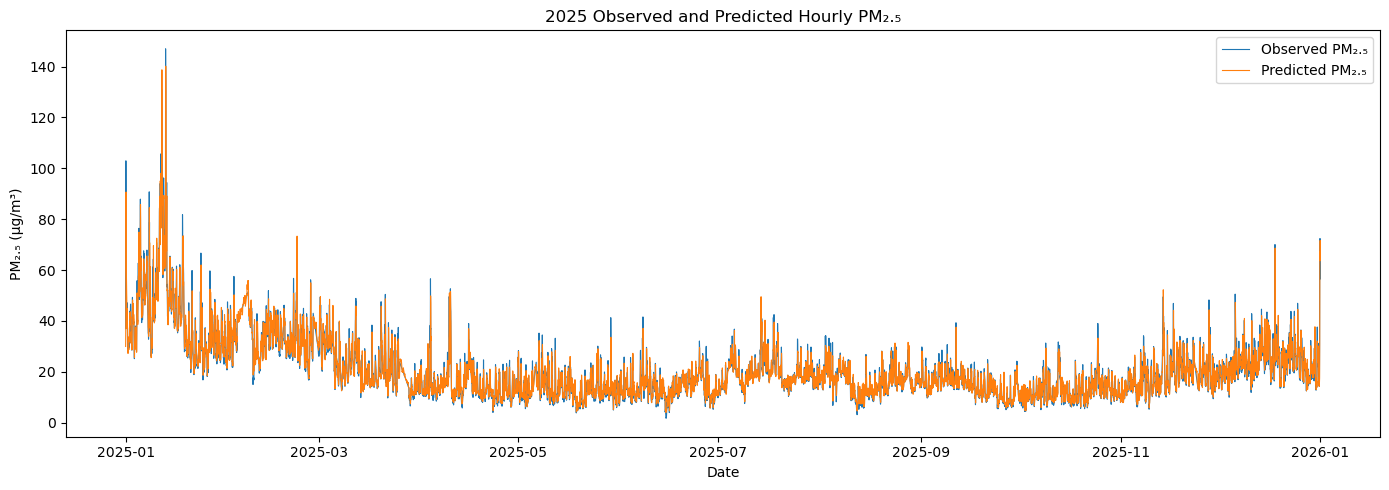

In [22]:
# 27. Plot 2025 observed versus predicted PM₂.₅

plt.figure(figsize=(14, 5))
plt.plot(
    predictions_2025["target_timestamp"],
    predictions_2025["observed_PM2.5"],
    label="Observed PM₂.₅",
    linewidth=0.8
)
plt.plot(
    predictions_2025["target_timestamp"],
    predictions_2025["predicted_PM2.5"],
    label="Predicted PM₂.₅",
    linewidth=0.8
)
plt.xlabel("Date")
plt.ylabel("PM₂.₅ (µg/m³)")
plt.title("2025 Observed and Predicted Hourly PM₂.₅")
plt.legend()
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "2025_observed_vs_predicted_pm25.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


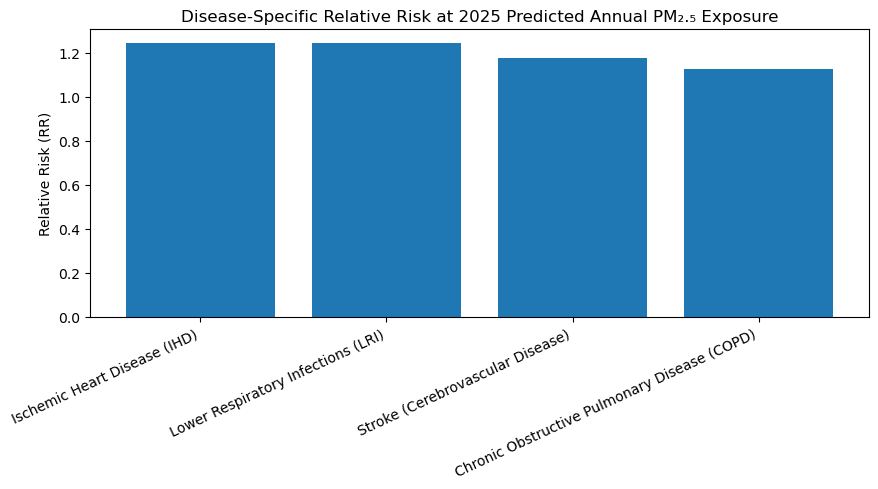

In [23]:
# 28. Plot disease-specific RR

plot_df = results.sort_values("RR", ascending=False).copy()

plt.figure(figsize=(9, 5))
plt.bar(
    plot_df["disease"],
    plot_df["RR"]
)
plt.ylabel("Relative Risk (RR)")
plt.title("Disease-Specific Relative Risk at 2025 Predicted Annual PM₂.₅ Exposure")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "disease_specific_rr.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


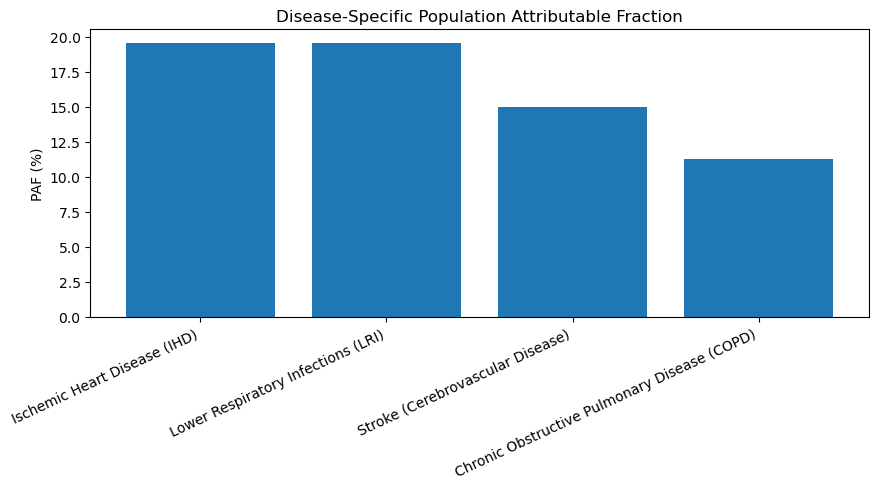

In [24]:
# 29. Plot disease-specific PAF

plot_df = results.sort_values("PAF", ascending=False).copy()

plt.figure(figsize=(9, 5))
plt.bar(
    plot_df["disease"],
    plot_df["PAF"] * 100
)
plt.ylabel("PAF (%)")
plt.title("Disease-Specific Population Attributable Fraction")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "disease_specific_paf.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


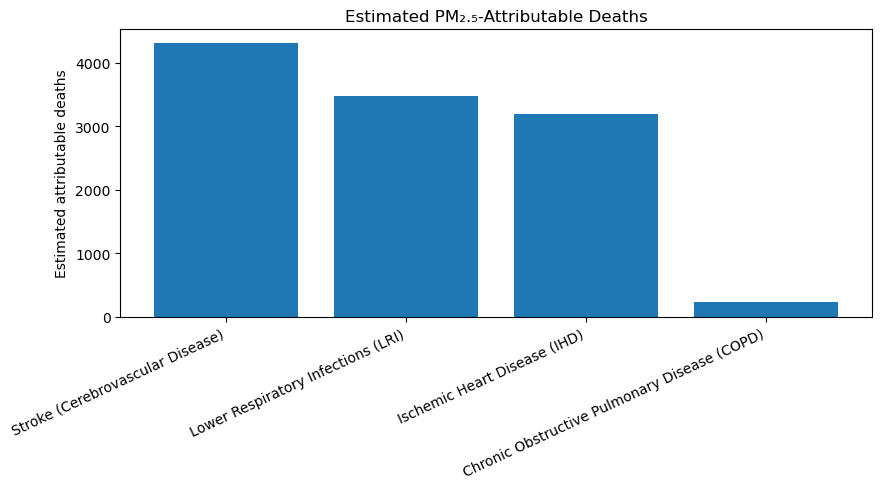

In [25]:
# 30. Plot attributable deaths

plot_df = results.sort_values("attributable_deaths", ascending=False).copy()

plt.figure(figsize=(9, 5))
plt.bar(
    plot_df["disease"],
    plot_df["attributable_deaths"]
)
plt.ylabel("Estimated attributable deaths")
plt.title("Estimated PM₂.₅-Attributable Deaths")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "attributable_deaths.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


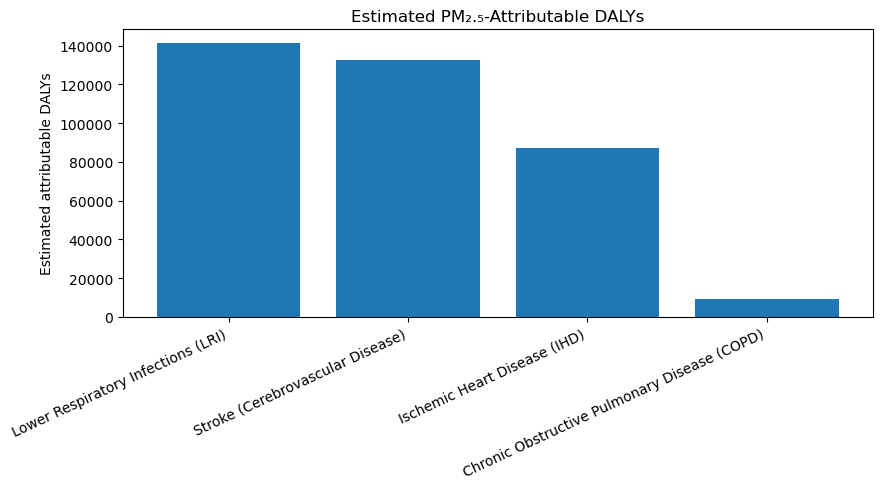

In [26]:
# 31. Plot attributable DALYs

plot_df = results.sort_values("attributable_dalys", ascending=False).copy()

plt.figure(figsize=(9, 5))
plt.bar(
    plot_df["disease"],
    plot_df["attributable_dalys"]
)
plt.ylabel("Estimated attributable DALYs")
plt.title("Estimated PM₂.₅-Attributable DALYs")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "attributable_dalys.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
